In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.layers import Dense,Input
from tensorflow.keras.models import Sequential
from sklearn.metrics import mean_squared_error,r2_score,accuracy_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Tensorflow is a high level library which provides classes, functions and methods to build various neural network architectures. It also autocomputes gradients for backpropagation and has various activation functions, neural network layers, like fully connected (dense), convolution, RNNs and so on. 
It also has various optimization functions which perform backpropagation. To summarize it has everything that you need to build, train and deploy a neural network

In [11]:
dataset = pd.read_csv('MELBOURNE_HOUSE_PRICES_LESS.csv',delimiter=',')
dataset.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Postcode,Regionname,Propertycount,Distance,CouncilArea
0,Abbotsford,49 Lithgow St,3,h,1490000.0,S,Jellis,1/04/2017,3067,Northern Metropolitan,4019,3.0,Yarra City Council
1,Abbotsford,59A Turner St,3,h,1220000.0,S,Marshall,1/04/2017,3067,Northern Metropolitan,4019,3.0,Yarra City Council
2,Abbotsford,119B Yarra St,3,h,1420000.0,S,Nelson,1/04/2017,3067,Northern Metropolitan,4019,3.0,Yarra City Council
3,Aberfeldie,68 Vida St,3,h,1515000.0,S,Barry,1/04/2017,3040,Western Metropolitan,1543,7.5,Moonee Valley City Council
4,Airport West,92 Clydesdale Rd,2,h,670000.0,S,Nelson,1/04/2017,3042,Western Metropolitan,3464,10.4,Moonee Valley City Council


In [12]:
dataset = dataset.drop(columns=['Suburb','Address','CouncilArea','Method'])

In [13]:
dataset.dropna(inplace=True)

/tmp/ipykernel_18402/2639109627.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dataset.dropna(inplace=True)


In [14]:
dataset = pd.get_dummies(dataset, drop_first=True)

In [15]:
dataset.head()

,Rooms,Price,Postcode,Propertycount,Distance,Type_t,Type_u,SellerG_A,SellerG_AIME,SellerG_ASL,...,Date_9/06/2018,Date_9/09/2017,Date_9/12/2017,Regionname_Eastern Victoria,Regionname_Northern Metropolitan,Regionname_Northern Victoria,Regionname_South-Eastern Metropolitan,Regionname_Southern Metropolitan,Regionname_Western Metropolitan,Regionname_Western Victoria
0,3,1490000.0,3067,4019,3.0,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
1,3,1220000.0,3067,4019,3.0,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
2,3,1420000.0,3067,4019,3.0,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
3,3,1515000.0,3040,1543,7.5,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,2,670000.0,3042,3464,10.4,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False


In [16]:
scalerx = MinMaxScaler()
scalery = MinMaxScaler()

x = scalerx.fit_transform(dataset.drop(['Price'],axis=1))
y = scalery.fit_transform(np.reshape(dataset['Price'],(len(dataset),1)))

In [17]:
x_train,x_test,y_train,y_test = train_test_split(x,np.squeeze(y),test_size=0.2,random_state=27)

In [18]:
x_train.shape

(38746, 545)

Sequential model basically makes a model which has input followed by hiddden layer and output. No in between inputs and extra outputs. Non sequential model is also possible in tensflow where you can provide mulitple distinct inputs at different layers and multiple outputs. You can also have shared layers. It can be built by the functional api which can be found in tensorflow documentation. 

The number of neurons in input depends on number of features in your data. In this case you have 38746 samples in training set and each sample has 545 features. Therefore your input shape will be (number features,). 

Similarly your output neurons will be equal to output features.

In case of a 2D cnn, the input shape will be (height x width x channels) for an image.

In [19]:
# Define a FFNN using Tensorflow.

# initialize a object named model from Tensorflow Sequential model class.
model = Sequential()

#model.add(Input(shape= (x_train.shape[1],)))
# # First layer should always have an input shape to build the model. 
model.add(Dense(5,activation='relu',use_bias=True,input_shape=(x_train.shape[1],)))

# use_bias is by default True, so you dont need to use it explicitly.
model.add(Dense(15,activation='relu'))
model.add(Dense(15,activation='relu'))
model.add(Dense(15,activation='relu'))
model.add(Dense(15,activation='relu'))
model.add(Dense(15,activation='relu'))

# Final layer should have neurons equal to number of outputs. While using relu, final layer should have 
# a non-relu activation
model.add(Dense(1,activation='sigmoid'))

/home/nam/miniconda3/envs/cie26/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1793887695.092618   18402 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In case of classification, use sigmoid or softmax in the final layers as you need to get the probability of data belonging to a certain class and not curve fitting.

In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 5)              │         2,730 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │            90 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 15)             │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 15)             │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 15)             │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,796 (14.83 KB)

 Trainable params: 3,796 (14.83 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile the built model with optimizer, loss and metrics
adam = tf.keras.optimizers.Adam(learning_rate=1e-5)

#adam = tf.keras.optimizers.legacy.Adam(learning_rate=1e-5)... for mac users
model.compile(optimizer=adam,loss='mse',metrics=['mse','mae'])

In [22]:
history = model.fit(x_train,y_train.reshape(len(x_train),1),
                    epochs=20,batch_size=32,validation_data=(x_test,y_test))

Epoch 1/20
1211/1211 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - loss: 0.1693 - mae: 0.4081 - mse: 0.1693 - val_loss: 0.1587 - val_mae: 0.3948 - val_mse: 0.1587
Epoch 2/20
1211/1211 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.1440 - mae: 0.3755 - mse: 0.1440 - val_loss: 0.1265 - val_mae: 0.3516 - val_mse: 0.1265
Epoch 3/20
1211/1211 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.1043 - mae: 0.3177 - mse: 0.1043 - val_loss: 0.0805 - val_mae: 0.2785 - val_mse: 0.0805
Epoch 4/20
1211/1211 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.0571 - mae: 0.2309 - mse: 0.0571 - val_loss: 0.0360 - val_mae: 0.1823 - val_mse: 0.0360
Epoch 5/20
1211/1211 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.0221 - mae: 0.1379 - mse: 0.0221 - val_loss: 0.0121 - val_mae: 0.0999 - val_mse: 0.0121
Epoch 6/20
1211/1211 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.0076 - mae: 0.0755 - mse: 0.0076 - val_loss: 0.0050 - val_mae: 0.0578 - val_mse: 0.0050
Epoch 7/20
1211/1211 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.0039 - mae: 0.0488 - mse

In [23]:
hist = pd.DataFrame(history.history)

In [24]:
hist.head()

,loss,mae,mse,val_loss,val_mae,val_mse
0,0.169309,0.408093,0.169309,0.158692,0.394755,0.158692
1,0.143972,0.375512,0.143972,0.126517,0.351583,0.126517
2,0.104318,0.317664,0.104318,0.080472,0.278509,0.080472
3,0.057088,0.230925,0.057088,0.036039,0.182318,0.036039
4,0.022098,0.137912,0.022098,0.012121,0.099882,0.012121


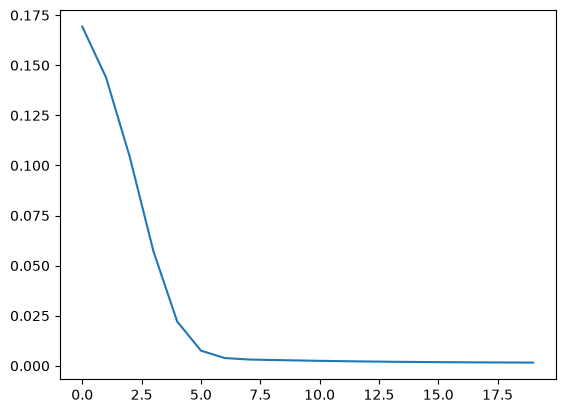

In [25]:
plt.plot(hist['loss'])